In [1]:
import torch
from torch.utils.data import random_split, DataLoader
from rating_dataset import *
from model import *
from loss import * 
from metrics import *
from PIL import Image
import re
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP
from utils import *
import matplotlib.pyplot as plt
import math
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
from scipy.stats import spearmanr
def run_epoch(model, loader, criterion, device, optimizer=None, ema=None):
    """
    optimizer != None: 训练
    optimizer == None: 验证
    模型输出 logits，形状为 (B, 10)
    """
    is_train = optimizer is not None
    if is_train:
        model.train()
    else:
        model.eval()
    total_loss = 0.0
    total_emd = 0.0
    total_mae = 0.0
    total_nll = 0.0
    num_samples = 0
    all_pred_means = []
    all_true_means = []
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            batch_size = x.size(0)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            outputs = model(x, return_pair=is_train)
            loss = criterion(outputs, y)
            logits = outputs[0] if isinstance(outputs, (tuple, list)) else outputs
            if is_train:
                loss.backward()
                # 梯度裁剪
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], max_norm=1.0)
                optimizer.step()
                if ema is not None:
                    ema.update(model)
            # =================================
            # 计算四个独立评价指标
            # =================================
            with torch.no_grad():
                log_probs = F.log_softmax(logits.float(), dim=1)
                probs = log_probs.exp()
                target = y.float()
                # 1. EMD: r=2，与原始损失一致
                cdf_diff = probs.cumsum(dim=1)- target.cumsum(dim=1)
                emd_per_sample = cdf_diff.square().mean(dim=1).sqrt()
                # 2. 平均评分 MAE
                bins = torch.arange(1, 11,device=device,dtype=probs.dtype)
                pred_means = (probs * bins).sum(dim=1)
                true_means = (target * bins).sum(dim=1)
                mae_per_sample = (pred_means - true_means).abs()
                # 3. NLL：使用原始标签，不平滑
                nll_per_sample = -(target * log_probs).sum(dim=1)
                # 4. 累积整个数据集，用于 Spearman
                all_pred_means.extend(pred_means.cpu().tolist())
                all_true_means.extend(true_means.cpu().tolist())
                total_loss += loss.item() * batch_size
                total_emd += emd_per_sample.sum().item()
                total_mae += mae_per_sample.sum().item()
                total_nll += nll_per_sample.sum().item()
                num_samples += batch_size
    if num_samples == 0:
        raise ValueError("DataLoader 没有样本")
    # 在整个数据集上计算 Spearman
    pred_array = np.asarray(all_pred_means)
    true_array = np.asarray(all_true_means)
    if (num_samples < 2 or np.ptp(pred_array) < 1e-12 or np.ptp(true_array) < 1e-12):
        spearman = float("nan")
    else:
        spearman = float(spearmanr(pred_array, true_array).statistic)
    return {
        "loss": total_loss / num_samples,
        "emd": total_emd / num_samples,
        "mae": total_mae / num_samples,
        "nll": total_nll / num_samples,
        "spearman": spearman,
    }
class TrainableEMA:
    def __init__(self, model, decay=0.995):
        self.decay = decay
        self.shadow = {name: p.detach().clone() for name, p in model.named_parameters() if p.requires_grad}
        self.backup = {}
    @torch.no_grad()
    def update(self, model):
        for name, p in model.named_parameters():
            if name in self.shadow:
                self.shadow[name].lerp_(p.detach(), 1.0 - self.decay)
    @torch.no_grad()
    def apply(self, model):
        self.backup = {}
        for name, p in model.named_parameters():
            if name in self.shadow:
                self.backup[name] = p.detach().clone()
                p.copy_(self.shadow[name])
    @torch.no_grad()
    def restore(self, model):
        for name, p in model.named_parameters():
            if name in self.backup:
                p.copy_(self.backup[name])
        self.backup = {}

In [2]:
train_from_origin=True
weights_dir = Path("weights")
weights_dir.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("当前设备：", device)

当前设备： cuda


In [3]:
preprocess_face_dataset(src_dir="data/train_data", dst_dir="data/face_data", mask_dir="data/face_masks", size=448, expand=1.75)

D:\miniconda\envs\myenv\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\miniconda\envs\myenv\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


预处理完成：data\face_data


In [4]:
data_dir = "data/face_data"
mask_dir = "data/face_masks"
dataset = RatingDataset(data_dir, mask_dir=mask_dir)

In [5]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [6]:
train_subset, val_subset = random_split(dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))
train_dataset = RatingDataset(data_dir, mask_dir=mask_dir, indices=train_subset.indices, augment=False, repeat=1)
val_dataset = RatingDataset(data_dir, mask_dir=mask_dir, indices=val_subset.indices, augment=False, repeat=1)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)
print(f"训练集：{len(train_dataset)}")
print(f"验证集：{len(val_dataset)}")

训练集：2076
验证集：519


In [7]:
model = RatingNet(pretrained=True, dropout=0.5, train_last_stage=False, width=64, prior_mix=0.05, use_entropy=True, use_high_resolution=True, scales=(224, 336, 448, 560), grid_side=32).to(device)
criterion = TreeOrdinalLoss(nll_weight=1.0, emd_weight=2.5, mean_weight=0.5, rdrop_weight=0.1).to(device)
prior = torch.zeros(10)
for _, labels in DataLoader(train_subset, batch_size=64, shuffle=False):
    prior += labels.detach().float().sum(dim=0).cpu()
model.set_prior(prior)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=0.05)

Using cache found in C:\Users\Administrator/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\Administrator/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\Administrator/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\Administrator/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


In [8]:
if not train_from_origin:
    checkpoint = torch.load("weights/best.pth",map_location=device,weights_only=True,)
    model.load_state_dict(checkpoint)
    print("已加载权重")

In [9]:
import math
import torch
from pathlib import Path
epochs = 25
enable_finetune = False
best_path = "weights/best.pth"
Path(best_path).parent.mkdir(parents=True, exist_ok=True)
model = model.to(device)
criterion = criterion.to(device)
ema = TrainableEMA(model, decay=0.995)
min_emd = float("inf")
best_epoch = 0
lst_train_loss = []
lst_train_emd = []
lst_train_mae = []
lst_train_nll = []
lst_train_spearman = []
lst_val_loss = []
lst_val_emd = []
lst_val_mae = []
lst_val_nll = []
lst_val_spearman = []
head_epochs = min(5, epochs) if enable_finetune else epochs
finetune_epochs = max(0, epochs - head_epochs)
patience = 4
min_delta = 1e-4
current_epoch = 0
phases = [("冻结DINOv2训练多尺度图树网络", head_epochs, False), ("微调最后一个Transformer Block", finetune_epochs, True)]
for phase_name, phase_epochs, train_last_stage in phases:
    if phase_epochs == 0:
        continue
    print(f"\n========== {phase_name} ==========")
    if train_last_stage:
        model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    model.set_train_last_stage(train_last_stage)
    if not train_last_stage:
        decay_params = [p for name, p in model.named_parameters() if p.requires_grad and p.ndim >= 2]
        no_decay_params = [p for name, p in model.named_parameters() if p.requires_grad and p.ndim < 2]
        optimizer = torch.optim.AdamW([{"params": decay_params, "weight_decay": 0.1}, {"params": no_decay_params, "weight_decay": 0.0}], lr=5e-5)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=phase_epochs, eta_min=1e-6)
    else:
        tree_params = [p for name, p in model.named_parameters() if not name.startswith("backbone.") and p.requires_grad]
        optimizer = torch.optim.AdamW([{"params": model.backbone.blocks[-1].parameters(), "lr": 2e-6}, {"params": model.backbone.norm.parameters(), "lr": 3e-6}, {"params": tree_params, "lr": 2e-5}], weight_decay=0.03)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=phase_epochs, eta_min=1e-7)
    no_improve = 0
    for phase_epoch in range(phase_epochs):
        current_epoch += 1
        train_metrics = run_epoch(model=model, loader=train_loader, criterion=criterion, device=device, optimizer=optimizer, ema=None)
        #ema.apply(model)
        val_metrics = run_epoch(model=model, loader=val_loader, criterion=criterion, device=device, optimizer=None)
        lst_train_loss.append(train_metrics["loss"])
        lst_train_emd.append(train_metrics["emd"])
        lst_train_mae.append(train_metrics["mae"])
        lst_train_nll.append(train_metrics["nll"])
        lst_train_spearman.append(train_metrics["spearman"])
        lst_val_loss.append(val_metrics["loss"])
        lst_val_emd.append(val_metrics["emd"])
        lst_val_mae.append(val_metrics["mae"])
        lst_val_nll.append(val_metrics["nll"])
        lst_val_spearman.append(val_metrics["spearman"])
        print(f"\nEpoch {current_epoch}/{epochs}")
        print(f"训练集 Loss={train_metrics['loss']:.4f} | EMD={train_metrics['emd']:.4f} | MAE={train_metrics['mae']:.4f} | NLL={train_metrics['nll']:.4f} | Spearman={train_metrics['spearman']:.4f}")
        print(f"验证集 Loss={val_metrics['loss']:.4f} | EMD={val_metrics['emd']:.4f} | MAE={val_metrics['mae']:.4f} | NLL={val_metrics['nll']:.4f} | Spearman={val_metrics['spearman']:.4f}")
        current_emd = float(val_metrics["emd"])
        if not math.isfinite(current_emd):
            raise ValueError(f"Epoch {current_epoch} 验证EMD不是有限数值")
        if current_emd < min_emd - min_delta:
            min_emd = current_emd
            best_epoch = current_epoch
            no_improve = 0
            torch.save(model.state_dict(), best_path)
            print(f"最好权重已保存，验证EMD={min_emd:.6f}")
        else:
            no_improve += 1
        #ema.restore(model)
        scheduler.step()
        print(f"当前学习率：{[round(group['lr'], 9) for group in optimizer.param_groups]}")
        print(f"连续未改善轮数：{no_improve}/{patience}")
        if no_improve >= patience:
            print(f"Early Stopping：连续{patience}个Epoch验证EMD未显著改善")
            break
model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
model.eval()
print("\n训练结束")
print(f"最佳Epoch：{best_epoch}")
print(f"最佳验证EMD：{min_emd:.6f}")
print(f"最佳权重路径：{best_path}")
print(f"多尺度融合权重：{model.get_scale_weights()}")



========== 冻结DINOv2训练多尺度图树网络 ==========

Epoch 1/25
训练集 Loss=2.6876 | EMD=0.2562 | MAE=1.2752 | NLL=1.9856 | Spearman=0.1531
验证集 Loss=2.5399 | EMD=0.2391 | MAE=1.1710 | NLL=1.9000 | Spearman=0.3512
最好权重已保存，验证EMD=0.239063
当前学习率：[4.9807e-05, 4.9807e-05]
连续未改善轮数：0/4

Epoch 2/25
训练集 Loss=2.6016 | EMD=0.2460 | MAE=1.2154 | NLL=1.9338 | Spearman=0.2843
验证集 Loss=2.4980 | EMD=0.2341 | MAE=1.1405 | NLL=1.8720 | Spearman=0.3918
最好权重已保存，验证EMD=0.234079
当前学习率：[4.923e-05, 4.923e-05]
连续未改善轮数：0/4

Epoch 3/25
训练集 Loss=2.5666 | EMD=0.2410 | MAE=1.1727 | NLL=1.9045 | Spearman=0.3683
验证集 Loss=2.4780 | EMD=0.2316 | MAE=1.1227 | NLL=1.8589 | Spearman=0.4131
最好权重已保存，验证EMD=0.231575
当前学习率：[4.828e-05, 4.828e-05]
连续未改善轮数：0/4

Epoch 4/25
训练集 Loss=2.5324 | EMD=0.2379 | MAE=1.1468 | NLL=1.8859 | Spearman=0.4050
验证集 Loss=2.4632 | EMD=0.2306 | MAE=1.1261 | NLL=1.8471 | Spearman=0.4233
最好权重已保存，验证EMD=0.230551
当前学习率：[4.697e-05, 4.697e-05]
连续未改善轮数：0/4

Epoch 5/25
训练集 Loss=2.5031 | EMD=0.2356 | MAE=1.1373 | NLL=1.8648 | 

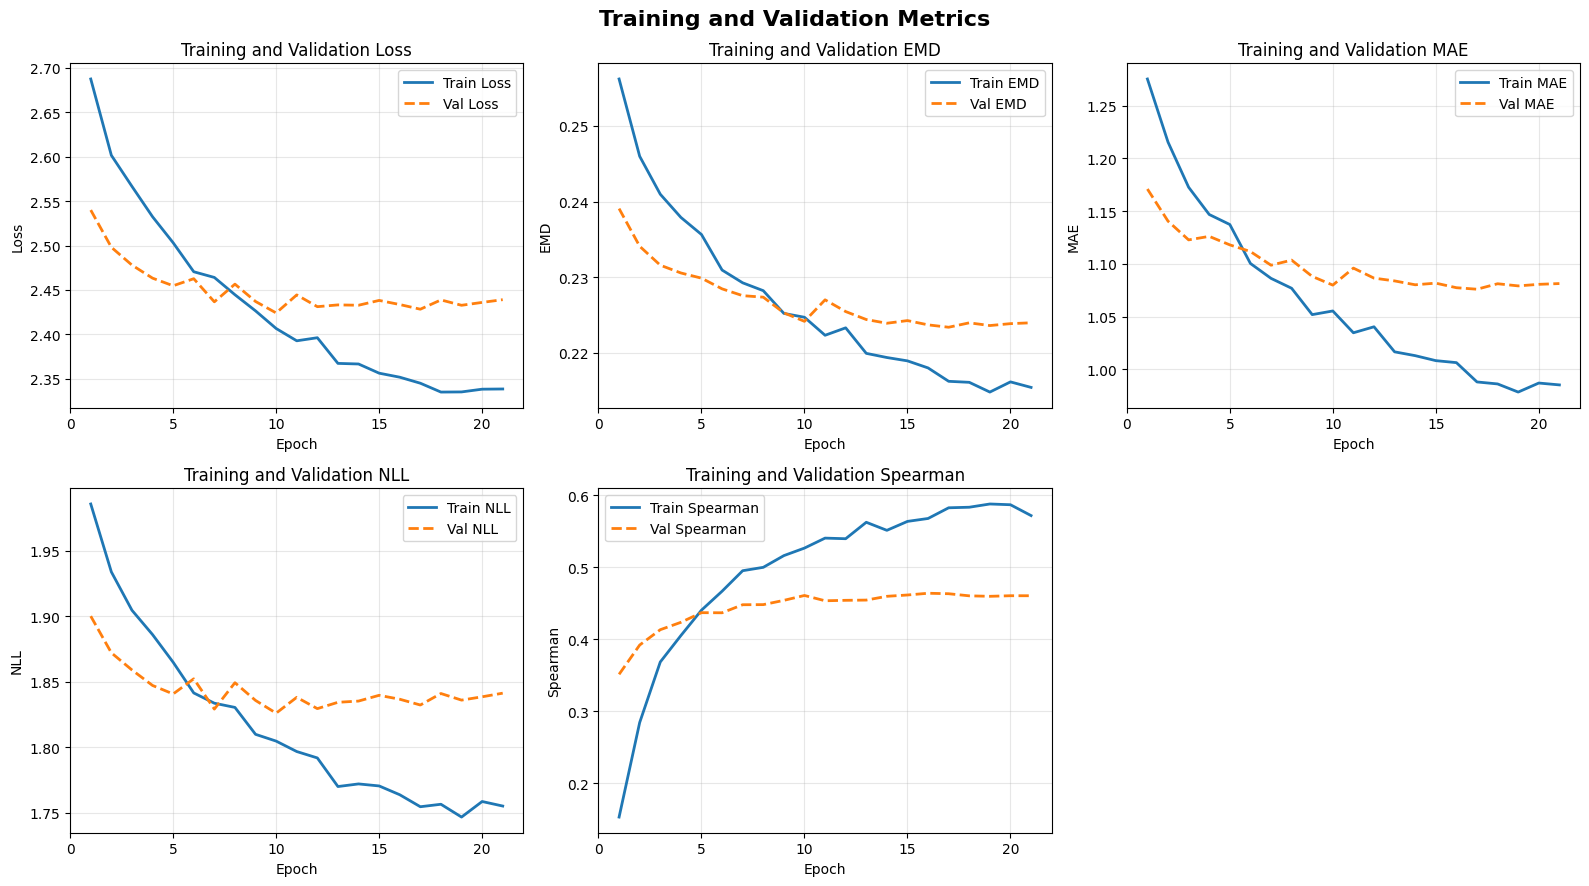

In [10]:
draw_train_val_loss(
    lst_train_emd=lst_train_emd,
    lst_train_mae=lst_train_mae,
    lst_val_emd=lst_val_emd,
    lst_val_mae=lst_val_mae,
    lst_train_loss=lst_train_loss,
    lst_val_loss=lst_val_loss,
    lst_train_nll=lst_train_nll,
    lst_val_nll=lst_val_nll,
    lst_train_spearman=lst_train_spearman,
    lst_val_spearman=lst_val_spearman,
    save=True
)

In [18]:
import importlib
import utils
importlib.reload(utils)
from utils import *

真实标签为: tensor([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.], device='cuda:0')
预测概率分布为: tensor([0.0189, 0.0516, 0.1599, 0.3087, 0.2796, 0.1261, 0.0394, 0.0107, 0.0032,
        0.0019], device='cuda:0')
概率之和为: 1.000000
预测平均评分为: 4.4003


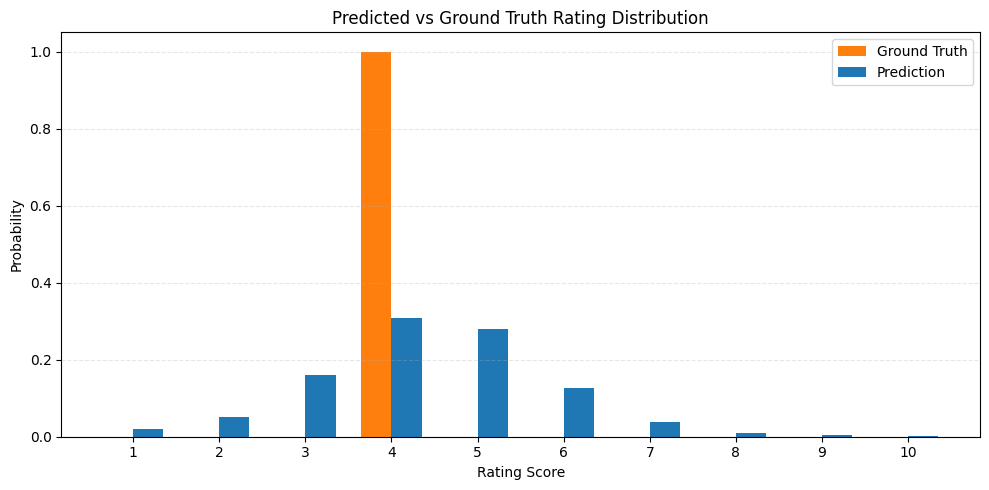

In [20]:
visualize_sample(1940,model,device)

真实标签为: tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.6667, 0.3333, 0.0000, 0.0000,
        0.0000], device='cuda:0')
预测概率分布为: tensor([0.0044, 0.0130, 0.0486, 0.1501, 0.3113, 0.2958, 0.1276, 0.0361, 0.0093,
        0.0037], device='cuda:0')
概率之和为: 1.000000
预测平均评分为: 5.4109


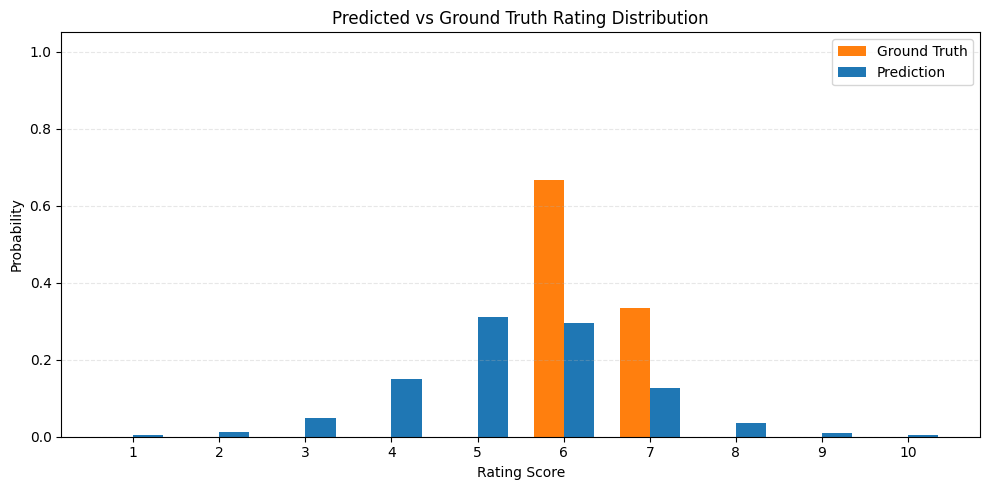

In [21]:
visualize_sample(1941,model,device)

真实标签为: tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')
预测概率分布为: tensor([0.0570, 0.1817, 0.3757, 0.2677, 0.0854, 0.0225, 0.0063, 0.0017, 0.0009,
        0.0011], device='cuda:0')
概率之和为: 1.000000
预测平均评分为: 3.2571


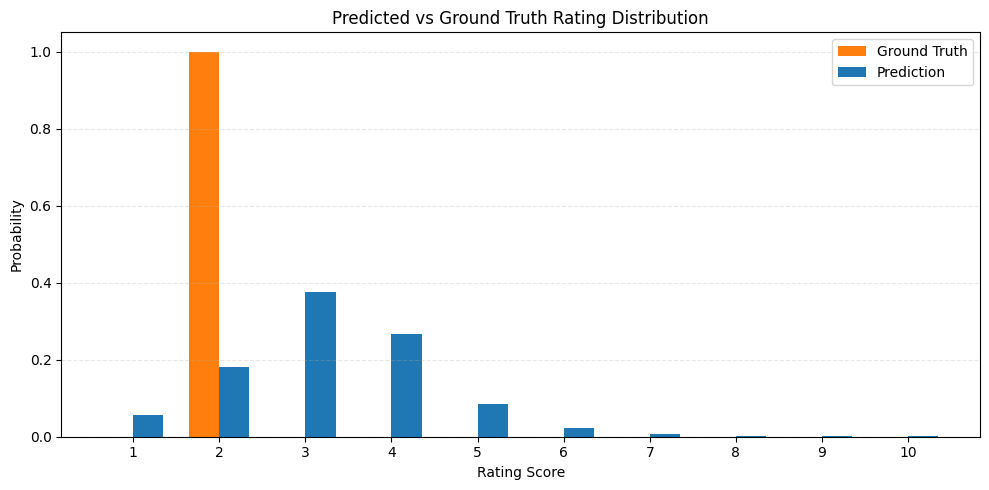

In [22]:
visualize_sample(1942,model,device)

真实标签为: tensor([0.0000, 0.0000, 0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000], device='cuda:0')
预测概率分布为: tensor([0.0092, 0.0321, 0.1272, 0.3196, 0.3289, 0.1360, 0.0354, 0.0080, 0.0022,
        0.0015], device='cuda:0')
概率之和为: 1.000000
预测平均评分为: 4.5398


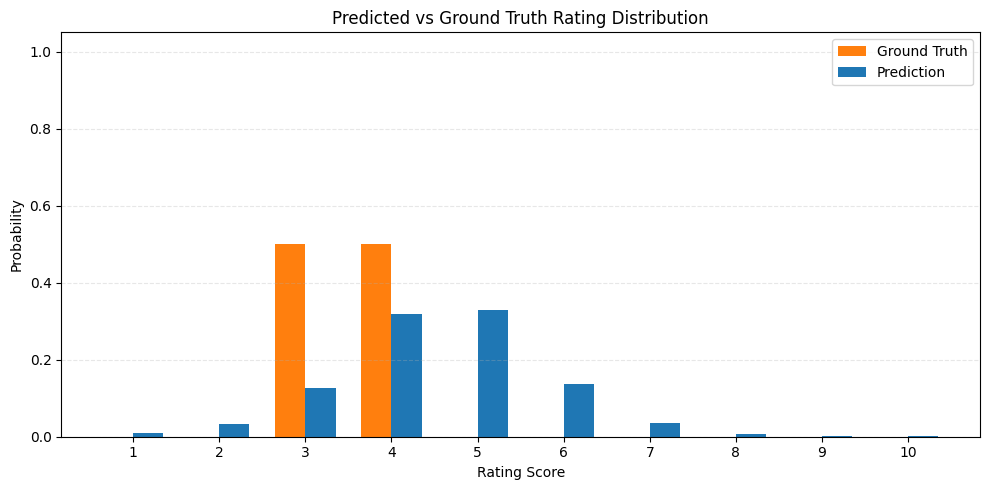

In [23]:
visualize_sample(1943,model,device)

真实标签为: tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.5000, 0.5000, 0.0000, 0.0000,
        0.0000], device='cuda:0')
预测概率分布为: tensor([0.0058, 0.0133, 0.0410, 0.1046, 0.2150, 0.2835, 0.2024, 0.0888, 0.0309,
        0.0147], device='cuda:0')
概率之和为: 1.000000
预测平均评分为: 5.9024


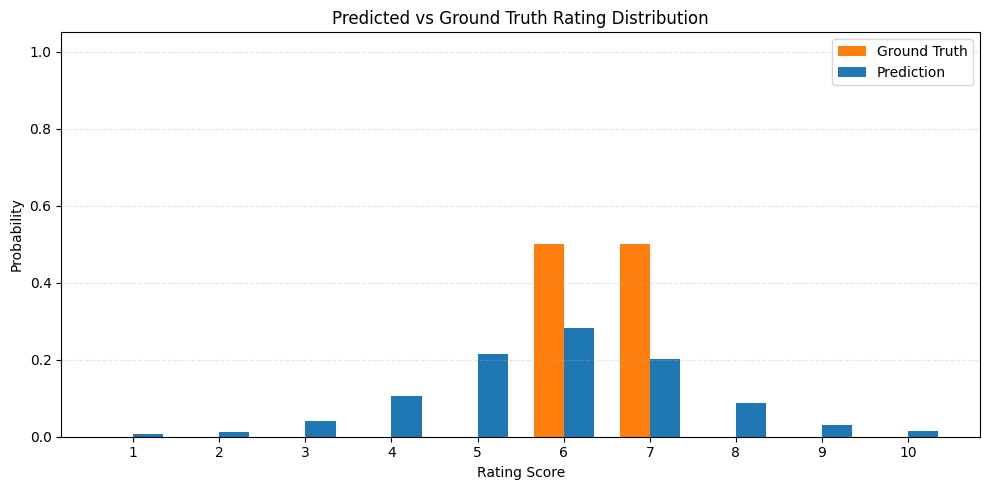

In [24]:
visualize_sample(1944,model,device)

真实标签为: tensor([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')
预测概率分布为: tensor([0.0607, 0.2136, 0.4069, 0.2325, 0.0622, 0.0160, 0.0048, 0.0014, 0.0008,
        0.0011], device='cuda:0')
概率之和为: 1.000000
预测平均评分为: 3.1087


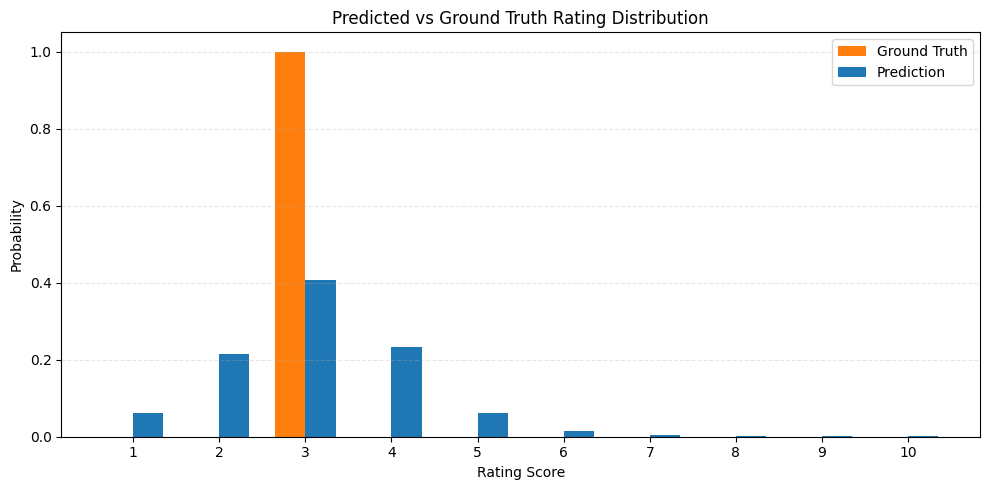

In [25]:
visualize_sample(1945,model,device)